# Las 100 islas más grandes del mundo

**Capítulo del curso:** Programar para responder (Open-Ended Project 1)

Preguntas que respondo con pandas:

1. ¿Cuáles son las 10 islas más grandes del trópico?
2. ¿Cuál es la isla más grande de cada región?
3. ¿Cómo cae el área a medida que baja el puesto del ranking?
4. ¿Qué islas se reparten entre varios países?

El área está en km².

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = Path("figuras")
FIG.mkdir(exist_ok=True)

In [2]:
islas = pd.read_csv("datos/largest-islands.csv").sort_values("rank")
print(islas.shape)
islas.head()

(100, 6)


,region,island,area,countries,climate,rank
41,Europe,Greenland,2166086,Denmark,polar,1
86,Oceania,New Guinea,821400,"Papua New Guinea, Indonesia",tropics,2
23,Asia,Borneo,755000,"Indonesia, Malaysia, Brunei",tropics,3
0,Africa,Madagascar,591896,Madagascar,tropics,4
75,North America,Baffin Island,507451,Canada,polar,5


## 1. Las 10 islas más grandes del trópico

In [3]:
tropicales = islas.query("climate == 'tropics'").head(10)
tropicales[["rank", "island", "countries", "area"]].reset_index(drop=True)

,rank,island,countries,area
0,2,New Guinea,"Papua New Guinea, Indonesia",821400
1,3,Borneo,"Indonesia, Malaysia, Brunei",755000
2,4,Madagascar,Madagascar,591896
3,6,Sumatra,Indonesia,480793
4,11,Sulawesi,Indonesia,188522
5,13,Java,Indonesia,129438
6,16,Cuba,Cuba,109884
7,17,Luzon,Philippines,104688
8,19,Mindanao,Philippines,94630
9,23,Hispaniola,"Dominican Republic, Haiti",76192


## 2. La isla más grande de cada región

In [4]:
mayor_por_region = islas.loc[islas.groupby("region")["area"].idxmax()]
mayor_por_region[["region", "island", "area"]].sort_values("area", ascending=False).reset_index(drop=True)

,region,island,area
0,Europe,Greenland,2166086
1,Oceania,New Guinea,821400
2,Asia,Borneo,755000
3,Africa,Madagascar,591896
4,North America,Baffin Island,507451
5,Eurasia,Sakhalin,76400
6,South America,Isla Grande de Tierra del Fuego,47992
7,Antarctic,Kerguelen,6200


## 3. Área según el puesto en el ranking

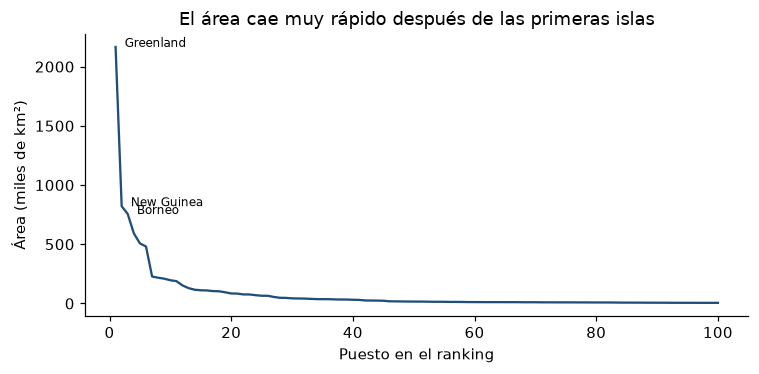

La 1.ª mide 11.0 veces la 10.ª y 409 veces la 100.ª.


In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(islas["rank"], islas["area"] / 1e3, color="#1f4e79")
ax.set_xlabel("Puesto en el ranking")
ax.set_ylabel("Área (miles de km²)")
ax.set_title("El área cae muy rápido después de las primeras islas")
for _, fila in islas.head(3).iterrows():
    ax.annotate(fila["island"], (fila["rank"], fila["area"] / 1e3), xytext=(6, 0), textcoords="offset points", fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "area-por-ranking.png", bbox_inches="tight")
plt.show()

print(f"La 1.ª mide {islas['area'].iloc[0] / islas['area'].iloc[9]:.1f} veces la 10.ª "
      f"y {islas['area'].iloc[0] / islas['area'].iloc[-1]:.0f} veces la 100.ª.")

## 4. Islas compartidas por varios países

In [6]:
compartidas = islas[islas["countries"].str.contains(",")]
compartidas[["rank", "island", "countries"]].reset_index(drop=True)

,rank,island,countries
0,2,New Guinea,"Papua New Guinea, Indonesia"
1,3,Borneo,"Indonesia, Malaysia, Brunei"
2,20,Ireland,"Ireland, United Kingdom"
3,23,Hispaniola,"Dominican Republic, Haiti"
4,28,Isla Grande de Tierra del Fuego,"Chile, Argentina"
5,76,Cyprus,"Cyprus, United Kingdom"
6,91,Kerguelen,"Antarctic Lands, France"


## Extra: área total por clima

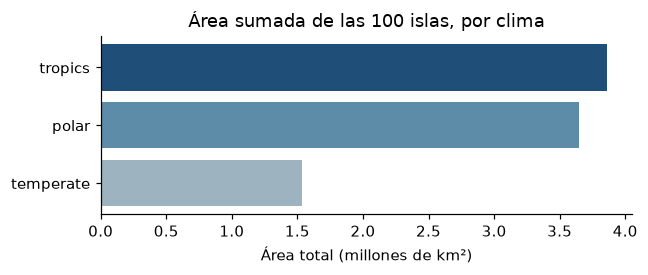

,count,sum
climate,,
temperate,32,1.534741
polar,27,3.645900
tropics,41,3.862144


In [7]:
por_clima = islas.groupby("climate")["area"].agg(["count", "sum"]).sort_values("sum")
por_clima["sum"] = por_clima["sum"] / 1e6

fig, ax = plt.subplots(figsize=(6, 2.6))
ax.barh(por_clima.index, por_clima["sum"], color=["#9db4c0", "#5c8ca8", "#1f4e79"])
ax.set_xlabel("Área total (millones de km²)")
ax.set_title("Área sumada de las 100 islas, por clima")
fig.tight_layout()
fig.savefig(FIG / "area-por-clima.png", bbox_inches="tight")
plt.show()
por_clima

## Conclusiones

- **Nueva Guinea** es la isla tropical más grande (821 400 km²), seguida de **Borneo** y **Madagascar**.
- **Groenlandia** domina todo el ranking: mide unas 11 veces la décima isla y unas 400 veces la centésima.
  La curva muestra que unas pocas islas concentran casi todo el área.
- Siete islas se reparten entre varios países: Borneo tiene tres (Indonesia, Malasia y Brunéi) y Nueva Guinea,
  La Española o Tierra del Fuego, dos.
- El trópico tiene más islas (41) y también la mayor área sumada. Groenlandia sola, la mayor de las polares,
  supera el área de las 32 islas templadas juntas.